# v2.0 Fast Demo：全序列建图（gap=3）+ Query

1. 使用 `test_data` **全部**立体同步序列  
2. `rig_pairs`：每秒 1 keyframe，**`max_temporal_gap=3`**（无 cross-camera）  
3. `feature_pairs`：DISK + LightGlue + INS 三角化 → `sfm/`、`global_features.h5`  
4. 从未参与建图的帧中均匀抽 **100** 帧 query  

**Kernel：** `SchubKI v2.0` · `source v2.0/scripts/env.sh`  
**输出：** `test/outputs/full_seq_gap3_rig/`


## 0. 环境与路径

In [43]:
import os
import sys
import time
from pathlib import Path

import numpy as np

TEST_DIR = Path.cwd().resolve()
V2_ROOT = TEST_DIR.parent
sys.path.insert(0, str(V2_ROOT / "src"))

HLOC_ROOT = V2_ROOT / "third_party" / "Hierarchical-Localization"
sys.path.insert(0, str(HLOC_ROOT))
os.environ.setdefault("HLOC_ROOT", str(HLOC_ROOT))
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

torch_hub = V2_ROOT / "model_cache" / "torch_hub"
torch_hub.mkdir(parents=True, exist_ok=True)
import torch

torch.hub.set_dir(str(torch_hub))

from robotcar.paths import DEFAULT_LEFT_IMAGES, DEFAULT_RIGHT_IMAGES
from robotcar.stereo import sync_stereo_pairs

OUTPUT_DIR = V2_ROOT / "test" / "outputs" / "full_seq_gap3_rig"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

NUM_QUERIES = 100
QUERY_CAMERA = "left"
RETRIEVAL_TOP_K = 5

print("OUTPUT:", OUTPUT_DIR)
print(f"NUM_QUERIES={NUM_QUERIES}, RETRIEVAL_TOP_K={RETRIEVAL_TOP_K}, camera={QUERY_CAMERA}")


OUTPUT: /Users/hbai/SchubKI/v2.0/test/outputs/full_seq_gap3_rig
NUM_QUERIES=100, RETRIEVAL_TOP_K=5, camera=left


## 1. 截取全部 ts 序列


In [44]:
KEYFRAME_INTERVAL_US = 1_000_000  # 1 Hz
MAX_TEMPORAL_GAP = 3

synced = sync_stereo_pairs(DEFAULT_LEFT_IMAGES, DEFAULT_RIGHT_IMAGES)
all_ts = [p[0] for p in synced]
print(f"全序列: {len(all_ts)} 帧, 时长 {(all_ts[-1] - all_ts[0]) / 1e6:.1f} s")

# 建图 / query 候选均使用全部同步帧（不再截 2 min 片段）
START_TS = all_ts[0]
segment_ts = list(all_ts)
SEGMENT_DURATION_US = None  # full sequence → KeyframeConfig 不截断
print(
    f"建图范围: start={START_TS}, 帧数={len(segment_ts)}, "
    f"时长≈{(segment_ts[-1] - segment_ts[0]) / 1e6:.1f} s"
)
print("max_temporal_gap:", MAX_TEMPORAL_GAP)


全序列: 2929 帧, 时长 192.0 s
建图范围: start=1400075224469383, 帧数=2929, 时长≈192.0 s
max_temporal_gap: 3


## 2. `rig_pairs`（`max_temporal_gap=3`，无 cross-camera）

In [45]:
from rig_pairs import KeyframeConfig, PairsConfig, generate_pairs_for_test_data

kf_cfg = KeyframeConfig(
    # full sequence: no start_ts / segment_duration_us truncation
    keyframe_interval_us=KEYFRAME_INTERVAL_US,
)
pc_cfg = PairsConfig(
    max_temporal_gap=MAX_TEMPORAL_GAP,
    min_baseline_m=0.75,
    include_cross_camera=False,
)
keyframes, pair_lists, pair_paths = generate_pairs_for_test_data(
    output_dir=OUTPUT_DIR,
    keyframe_config=kf_cfg,
    pairs_config=pc_cfg,
)
print(f"Keyframes: {len(keyframes)}, pairs-all: {len(pair_lists.all_pairs)}")
print(
    f"  stereo={len(pair_lists.stereo)}, "
    f"temporal_L={len(pair_lists.temporal_left)}, "
    f"temporal_R={len(pair_lists.temporal_right)}, "
    f"cross={len(pair_lists.cross)}"
)
for k in keyframes[:3]:
    print(f"  [{k.index}] ts={k.ts}")
print("  ...")
print(f"  [{keyframes[-1].index}] ts={keyframes[-1].ts}")


Keyframes: 181, pairs-all: 1203
  stereo=181, temporal_L=511, temporal_R=511, cross=0
  [0] ts=1400075224469383
  [1] ts=1400075225531740
  [2] ts=1400075226594096
  ...
  [180] ts=1400075416193447


## 3. `feature_pairs` → SfM

DISK + LightGlue（建图仍用 LightGlue）+ INS 三角化 + NetVLAD。  
续跑可设 `overwrite_features=False`。

In [46]:
from hloc.utils.device import inference_device
from feature_pairs import FeaturePairsConfig, FeaturePairsPaths, run_feature_pairs_pipeline

print("DISK / LightGlue device:", inference_device())

t0 = time.perf_counter()
fp_cfg = FeaturePairsConfig(
    paths=FeaturePairsPaths(rig_sfm_dir=OUTPUT_DIR),
    overwrite_features=False,
    build_reference=True,
    run_triangulation=True,
    build_global_descriptors=True,
)
fp_result = run_feature_pairs_pipeline(fp_cfg)
print(f"feature_pairs elapsed: {time.perf_counter() - t0:.1f} s")
print(fp_result.graph)
if fp_result.validation:
    print("points3D:", fp_result.validation.num_points3D)
    print("mean reproj:", fp_result.validation.mean_reprojection_error)
model = fp_result.model
assert model is not None

[2026/10/16 12:19:28 hloc INFO] Extracting features (cached model):
{'name': 'disk', 'max_keypoints': 5000}


DISK / LightGlue device: mps


/Users/hbai/SchubKI/v2.0/.venv-schubki-v2/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
[2026/10/16 12:19:28 hloc INFO] Cached extractor disk on mps
100%|██████████| 362/362 [03:03<00:00,  1.97it/s]
[2026/10/16 12:22:32 hloc INFO] Finished exporting features.
[2026/10/16 12:22:32 hloc INFO] Matching features (cached model):
{'name': 'lightglue', 'features': 'disk'}
[2026/10/16 12:22:33 hloc INFO] Cached matcher lightglue on mps
100%|██████████| 1203/1203 [15:55<00:00,  1.26it/s]
[2026/10/16 12:38:29 hloc INFO] Finished exporting matches.
[2026/10/16 12:38:29 hloc INFO] Extracting features (cached model):
{'name': 'netvlad'}
[2026/10/16 12:38:35 hloc INFO] Cached extractor netvlad on mps
100%|██████████| 362/362 [02:04<00:00,  2.92it/s]
[2026/10/16 12:40:39 hloc INFO] Finished exporting features.
[2026/10/16 12:40:39 hloc INFO] Importing features into the datab

feature_pairs elapsed: 1286.8 s
KeyframeGraphSummary(num_keyframes=181, num_images=362, num_pairs=1203, num_stereo_pairs=181, num_temporal_pairs=1022, image_names=['left/1400075224469383.png', 'left/1400075225531740.png', 'left/1400075226594096.png', 'left/1400075227656425.png', 'left/1400075228718755.png', 'left/1400075229781087.png', 'left/1400075230843416.png', 'left/1400075231905828.png', 'left/1400075232968183.png', 'left/1400075234030574.png', 'left/1400075235092934.png', 'left/1400075236155266.png', 'left/1400075237217596.png', 'left/1400075238279926.png', 'left/1400075239342257.png', 'left/1400075240404585.png', 'left/1400075241466938.png', 'left/1400075242529297.png', 'left/1400075243591648.png', 'left/1400075244654006.png', 'left/1400075245778857.png', 'left/1400075246903707.png', 'left/1400075247966056.png', 'left/1400075249028432.png', 'left/1400075250090810.png', 'left/1400075251153141.png', 'left/1400075252278015.png', 'left/1400075253340430.png', 'left/1400075254402836.p

## 3b. 稀疏地图（可选）

In [47]:
from hloc.utils import viz_3d

fig_map = viz_3d.init_figure()
viz_3d.plot_reconstruction(
    fig_map, model, color="rgba(255,0,0,0.45)", name="mapping", points_rgb=True
)
fig_map.show()

## 4. 选取未参与建图的 query 图

从全序列中排除 keyframe 时间戳后，**均匀采样 `NUM_QUERIES`（默认 100）帧**（左目）。


In [48]:
keyframe_ts = {kf.ts for kf in keyframes}
candidates = [t for t in segment_ts if t not in keyframe_ts]
if not candidates:
    raise RuntimeError("No non-keyframe timestamps in segment; loosen keyframe interval")

if len(candidates) <= NUM_QUERIES:
    QUERY_TS_LIST = list(candidates)
else:
    idx = np.linspace(0, len(candidates) - 1, NUM_QUERIES, dtype=int)
    QUERY_TS_LIST = [candidates[i] for i in idx]

print(f"candidates (未参与建图 / non-keyframe): {len(candidates)}")
print(f"selected queries: {len(QUERY_TS_LIST)}  camera={QUERY_CAMERA}")
print("first/last:", QUERY_TS_LIST[0], QUERY_TS_LIST[-1])


candidates (未参与建图 / non-keyframe): 2748
selected queries: 100  camera=left
first/last: 1400075224531875 1400075416443407


## 5. Query localization

使用 `RETRIEVAL_TOP_K`（默认 5）+ `QueryConfig.fast`；对 §4 选出的 query 帧跑定位。


In [49]:
from query import QueryConfig, QueryImageSpec, QueryWorkspacePaths, run_query_localization

paths = QueryWorkspacePaths(rig_sfm_dir=OUTPUT_DIR)
q_cfg = QueryConfig.fast(paths, retrieval_top_k=RETRIEVAL_TOP_K)

q_results = []
rows = []
t_all = time.perf_counter()
for i, ts in enumerate(QUERY_TS_LIST):
    t0 = time.perf_counter()
    r = run_query_localization(
        QueryImageSpec(timestamp_us=ts, camera=QUERY_CAMERA),
        q_cfg,
    )
    dt = time.perf_counter() - t0
    q_results.append(r)
    err = None
    if r.predicted.success and r.predicted.cam_from_world is not None:
        err = float(
            np.linalg.norm(
                np.asarray(r.predicted.cam_from_world.translation)
                - np.asarray(r.gt_cam_from_world.translation)
            )
        )
    rows.append(
        {
            "i": i,
            "ts": ts,
            "ok": r.predicted.success,
            "inliers": r.predicted.num_inliers if r.predicted.success else 0,
            "corr": r.predicted.num_correspondences if r.predicted.success else 0,
            "err_m": err,
            "dt_s": dt,
        }
    )
    err_s = f"{err:.3f} m" if err is not None else "-"
    print(
        f"[{i+1:02d}/{len(QUERY_TS_LIST)}] ts={ts}  {dt:.1f}s  "
        f"ok={r.predicted.success}  inliers={rows[-1]['inliers']}/{rows[-1]['corr']}  err={err_s}"
    )

total = time.perf_counter() - t_all
n_ok = sum(1 for x in rows if x["ok"])
errs = [x["err_m"] for x in rows if x["err_m"] is not None]
print(f"\nTotal: {total:.1f} s  mean/query: {total/len(QUERY_TS_LIST):.1f} s")
print(f"Success: {n_ok}/{len(QUERY_TS_LIST)}")
if errs:
    print(f"Position error [m]: mean={np.mean(errs):.3f}  median={np.median(errs):.3f}  max={np.max(errs):.3f}")

# mid query for 3D viz
q_result = q_results[len(q_results) // 2]
print(f"\nViz query (mid): ts={QUERY_TS_LIST[len(QUERY_TS_LIST)//2]}  inliers={q_result.predicted.num_inliers}")


[2026/10/16 12:40:57 hloc INFO] Extracting features (cached model):
{'name': 'netvlad'}
100%|██████████| 1/1 [00:00<00:00,  1.02it/s]
[2026/10/16 12:40:58 hloc INFO] Finished exporting features.
[2026/10/16 12:40:58 hloc INFO] Extracting image pairs from a retrieval database.
[2026/10/16 12:40:58 hloc INFO] Found 5 pairs.
[2026/10/16 12:40:58 hloc INFO] Extracting features (cached model):
{'name': 'disk', 'max_keypoints': 5000}
100%|██████████| 1/1 [00:00<00:00,  1.05it/s]
[2026/10/16 12:40:59 hloc INFO] Finished exporting features.
[2026/10/16 12:40:59 hloc INFO] Matching features (cached model):
{'name': 'nearest_neighbor', 'do_mutual_check': True}
[2026/10/16 12:40:59 hloc INFO] Cached matcher nearest_neighbor on mps
100%|██████████| 5/5 [00:00<00:00,  5.93it/s]
[2026/10/16 12:41:00 hloc INFO] Finished exporting matches.
[2026/10/16 12:41:00 hloc INFO] Extracting features (cached model):
{'name': 'netvlad'}


[01/100] ts=1400075224531875  3.6s  ok=True  inliers=5/38  err=3.111 m


100%|██████████| 1/1 [00:00<00:00,  2.82it/s]
[2026/10/16 12:41:01 hloc INFO] Finished exporting features.
[2026/10/16 12:41:01 hloc INFO] Extracting image pairs from a retrieval database.
[2026/10/16 12:41:01 hloc INFO] Found 5 pairs.
[2026/10/16 12:41:01 hloc INFO] Extracting features (cached model):
{'name': 'disk', 'max_keypoints': 5000}
100%|██████████| 1/1 [00:00<00:00,  1.29it/s]
[2026/10/16 12:41:02 hloc INFO] Finished exporting features.
[2026/10/16 12:41:02 hloc INFO] Matching features (cached model):
{'name': 'nearest_neighbor', 'do_mutual_check': True}
100%|██████████| 5/5 [00:00<00:00, 14.43it/s]
[2026/10/16 12:41:02 hloc INFO] Finished exporting matches.
[2026/10/16 12:41:02 hloc INFO] Extracting features (cached model):
{'name': 'netvlad'}


[02/100] ts=1400075226281637  2.0s  ok=True  inliers=795/1234  err=0.106 m


100%|██████████| 1/1 [00:00<00:00,  3.20it/s]
[2026/10/16 12:41:03 hloc INFO] Finished exporting features.
[2026/10/16 12:41:03 hloc INFO] Extracting image pairs from a retrieval database.
[2026/10/16 12:41:03 hloc INFO] Found 5 pairs.
[2026/10/16 12:41:03 hloc INFO] Extracting features (cached model):
{'name': 'disk', 'max_keypoints': 5000}
100%|██████████| 1/1 [00:00<00:00,  1.11it/s]
[2026/10/16 12:41:04 hloc INFO] Finished exporting features.
[2026/10/16 12:41:04 hloc INFO] Matching features (cached model):
{'name': 'nearest_neighbor', 'do_mutual_check': True}
100%|██████████| 5/5 [00:00<00:00, 14.18it/s]
[2026/10/16 12:41:04 hloc INFO] Finished exporting matches.
[2026/10/16 12:41:04 hloc INFO] Extracting features (cached model):
{'name': 'netvlad'}


...

[98/100] ts=1400075412693933  3.4s  ok=True  inliers=147/265  err=0.256 m


100%|██████████| 1/1 [00:00<00:00,  2.01it/s]
[2026/10/16 12:44:49 hloc INFO] Finished exporting features.
[2026/10/16 12:44:49 hloc INFO] Extracting image pairs from a retrieval database.
[2026/10/16 12:44:49 hloc INFO] Found 5 pairs.
[2026/10/16 12:44:49 hloc INFO] Extracting features (cached model):
{'name': 'disk', 'max_keypoints': 5000}
100%|██████████| 1/1 [00:01<00:00,  1.01s/it]
[2026/10/16 12:44:50 hloc INFO] Finished exporting features.
[2026/10/16 12:44:50 hloc INFO] Matching features (cached model):
{'name': 'nearest_neighbor', 'do_mutual_check': True}
100%|██████████| 5/5 [00:00<00:00, 12.33it/s]
[2026/10/16 12:44:51 hloc INFO] Finished exporting matches.


[99/100] ts=1400075414568683  2.5s  ok=True  inliers=197/419  err=0.192 m


[2026/10/16 12:44:51 hloc INFO] Extracting features (cached model):
{'name': 'netvlad'}
100%|██████████| 1/1 [00:00<00:00,  2.00it/s]
[2026/10/16 12:44:52 hloc INFO] Finished exporting features.
[2026/10/16 12:44:52 hloc INFO] Extracting image pairs from a retrieval database.
[2026/10/16 12:44:52 hloc INFO] Found 5 pairs.
[2026/10/16 12:44:52 hloc INFO] Extracting features (cached model):
{'name': 'disk', 'max_keypoints': 5000}
100%|██████████| 1/1 [00:00<00:00,  1.16it/s]
[2026/10/16 12:44:53 hloc INFO] Finished exporting features.
[2026/10/16 12:44:53 hloc INFO] Matching features (cached model):
{'name': 'nearest_neighbor', 'do_mutual_check': True}
100%|██████████| 5/5 [00:00<00:00, 11.64it/s]
[2026/10/16 12:44:53 hloc INFO] Finished exporting matches.


[100/100] ts=1400075416443407  2.3s  ok=True  inliers=173/373  err=0.269 m

Total: 236.8 s  mean/query: 2.4 s
Success: 100/100
Position error [m]: mean=9.101  median=0.880  max=382.588

Viz query (mid): ts=1400075321268652  inliers=194


## 6. Query 结果表 + 误差分布

对每组 query 输出 **GT / Predicted** 位姿（translation + quaternion）与位置误差；并画误差直方图 / 箱线图。


Success: 100/100
Position error [m]: mean=9.1011  median=0.8801  std=48.5917  min=0.0182  max=382.5878


,i,ts,ok,err_m,inliers,corr,gt_tx,gt_ty,gt_tz,pred_tx,pred_ty,pred_tz,gt_qw,gt_qx,gt_qy,gt_qz,pred_qw,pred_qx,pred_qy,pred_qz
0,1,1400075224531875,True,3.1112,5,38,+0.1208,+1.1951,-1.7165,+2.6520,+2.5255,-0.4906,-0.49436,-0.48544,-0.51173,+0.50803,+0.21297,+0.58659,+0.70406,-0.33891
1,2,1400075226281637,True,0.1057,795,1234,+0.1395,+1.1696,-1.7406,+0.1235,+1.1858,-1.8439,-0.49444,-0.48537,-0.51172,+0.50803,-0.49267,-0.48599,-0.51028,+0.51060
2,3,1400075228156347,True,0.0433,793,1277,+0.1420,+1.1603,-1.8515,+0.1147,+1.1825,-1.8766,-0.49494,-0.48623,-0.51084,+0.50760,-0.49335,-0.48680,-0.50938,+0.51006
3,4,1400075230031045,True,1.3664,938,1043,+0.3248,+1.1530,-3.5797,+0.1282,+1.2043,-2.2284,+0.48692,+0.49718,+0.52284,-0.49230,-0.48585,-0.49684,-0.52202,+0.49456
4,5,1400075231780839,True,0.0612,866,1779,+0.7281,+1.2727,-7.9293,+0.7557,+1.3242,-7.9473,+0.47545,+0.50469,+0.55049,-0.46496,+0.47552,+0.50320,+0.55213,-0.46456
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,96,1400075408444376,True,1.7207,14,42,+9.1632,-1.7515,+26.9584,+8.0702,-2.6025,+27.9792,-0.62409,-0.32851,-0.38477,+0.59544,-0.62576,-0.31259,-0.40766,+0.58696
96,97,1400075410631583,True,0.5973,142,301,-0.8299,-0.9358,+16.5057,-0.9956,-0.5369,+16.0932,-0.54000,-0.43944,-0.50294,+0.51220,-0.54257,-0.44761,-0.50283,+0.50242
97,98,1400075412693933,True,0.2560,147,265,-0.0399,-0.3276,+6.0779,-0.1217,-0.3961,+5.8451,-0.54297,-0.43859,-0.48442,+0.52740,-0.54840,-0.43499,-0.48475,+0.52446
98,99,1400075414568683,True,0.1922,197,419,+0.3111,+0.0118,-0.7768,+0.2042,-0.0259,-0.6216,-0.51601,-0.46058,-0.48790,+0.53250,-0.52051,-0.46881,-0.48500,+0.52351


/var/folders/ql/1gy51g214m13pp10b9yrpphc0000gn/T/ipykernel_67234/2224081701.py:130: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(errs, vert=True, widths=0.45, patch_artist=True,


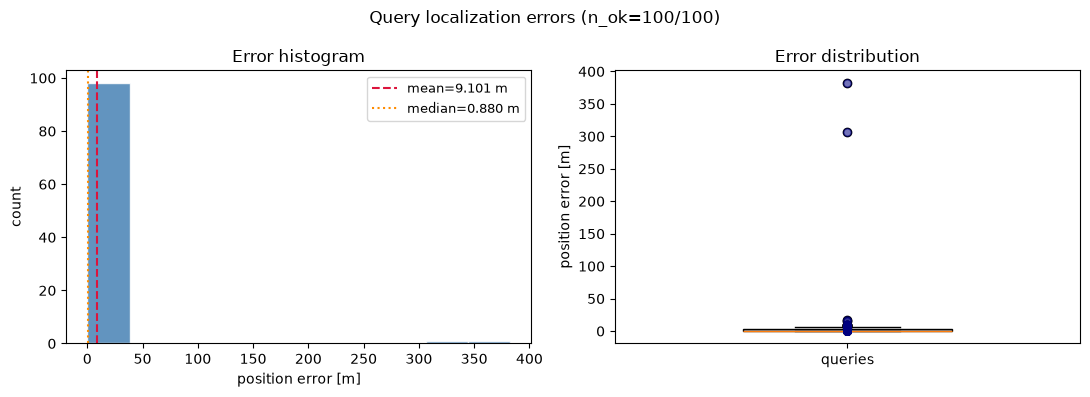

In [50]:
import pandas as pd
import matplotlib.pyplot as plt


def _t_q(pose):
    t = np.asarray(pose.translation, dtype=float)
    q = np.asarray(pose.rotation.quat, dtype=float)
    return t, q


rows = []
for i, (ts, r) in enumerate(zip(QUERY_TS_LIST, q_results)):
    gt_t, gt_q = _t_q(r.gt_cam_from_world)
    if r.predicted.success and r.predicted.cam_from_world is not None:
        pr_t, pr_q = _t_q(r.predicted.cam_from_world)
        err = float(np.linalg.norm(pr_t - gt_t))
        ok = True
        inl = r.predicted.num_inliers
        corr = r.predicted.num_correspondences
    else:
        pr_t = np.full(3, np.nan)
        pr_q = np.full(4, np.nan)
        err = np.nan
        ok = False
        inl = 0
        corr = 0
    rows.append(
        {
            "i": i + 1,
            "ts": ts,
            "ok": ok,
            "err_m": err,
            "inliers": inl,
            "corr": corr,
            "gt_tx": gt_t[0],
            "gt_ty": gt_t[1],
            "gt_tz": gt_t[2],
            "gt_qw": gt_q[0],
            "gt_qx": gt_q[1],
            "gt_qy": gt_q[2],
            "gt_qz": gt_q[3],
            "pred_tx": pr_t[0],
            "pred_ty": pr_t[1],
            "pred_tz": pr_t[2],
            "pred_qw": pr_q[0],
            "pred_qx": pr_q[1],
            "pred_qy": pr_q[2],
            "pred_qz": pr_q[3],
            "dt_s": None,
        }
    )

# attach per-query timings if present from §5 loop variable name clash — recompute from rows only
df = pd.DataFrame(rows)

# nicer display columns
disp = df[
    [
        "i",
        "ts",
        "ok",
        "err_m",
        "inliers",
        "corr",
        "gt_tx",
        "gt_ty",
        "gt_tz",
        "pred_tx",
        "pred_ty",
        "pred_tz",
        "gt_qw",
        "gt_qx",
        "gt_qy",
        "gt_qz",
        "pred_qw",
        "pred_qx",
        "pred_qy",
        "pred_qz",
    ]
].copy()
disp["err_m"] = disp["err_m"].map(lambda x: f"{x:.4f}" if pd.notna(x) else "-")
for col in [
    "gt_tx",
    "gt_ty",
    "gt_tz",
    "pred_tx",
    "pred_ty",
    "pred_tz",
]:
    disp[col] = disp[col].map(lambda x: f"{x:+.4f}" if pd.notna(x) else "-")
for col in [
    "gt_qw",
    "gt_qx",
    "gt_qy",
    "gt_qz",
    "pred_qw",
    "pred_qx",
    "pred_qy",
    "pred_qz",
]:
    disp[col] = disp[col].map(lambda x: f"{x:+.5f}" if pd.notna(x) else "-")

print(f"Success: {int(df['ok'].sum())}/{len(df)}")
errs = df.loc[df["ok"], "err_m"].astype(float)
if len(errs):
    print(
        f"Position error [m]: mean={errs.mean():.4f}  "
        f"median={errs.median():.4f}  std={errs.std():.4f}  "
        f"min={errs.min():.4f}  max={errs.max():.4f}"
    )

display(disp)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
if len(errs):
    ax.hist(errs, bins=min(10, max(5, len(errs))), color="steelblue", edgecolor="white", alpha=0.85)
    ax.axvline(errs.mean(), color="crimson", ls="--", label=f"mean={errs.mean():.3f} m")
    ax.axvline(errs.median(), color="darkorange", ls=":", label=f"median={errs.median():.3f} m")
    ax.legend(fontsize=9)
else:
    ax.text(0.5, 0.5, "no successful queries", ha="center", va="center", transform=ax.transAxes)
ax.set_xlabel("position error [m]")
ax.set_ylabel("count")
ax.set_title("Error histogram")

ax = axes[1]
if len(errs):
    ax.boxplot(errs, vert=True, widths=0.45, patch_artist=True,
               boxprops=dict(facecolor="lightsteelblue"))
    ax.scatter(np.ones(len(errs)), errs, color="navy", alpha=0.55, s=28, zorder=3)
    ax.set_ylabel("position error [m]")
else:
    ax.text(0.5, 0.5, "no successful queries", ha="center", va="center", transform=ax.transAxes)
ax.set_xticks([1])
ax.set_xticklabels(["queries"])
ax.set_title("Error distribution")

fig.suptitle(f"Query localization errors (n_ok={len(errs)}/{len(df)})", fontsize=12)
fig.tight_layout()
plt.show()

# keep for later cells
query_results_df = df


## 7. 全部 query：3D（地图点 + GT/预测相机锥）

- Plotly：SfM 三维点 + 全部 query 的 GT（蓝）与预测（绿）相机锥（`size=4`）
- 位姿数值表见上一节 §6


In [51]:
from hloc.utils import viz_3d

CAMERA_FRUSTUM_SIZE = 4.0  # larger cones (hloc default ~1)


def _pose_parts(pose):
    t = np.asarray(pose.translation, dtype=float)
    q = np.asarray(pose.rotation.quat, dtype=float)
    return t, q


def _print_pose(label: str, pose) -> None:
    t, q = _pose_parts(pose)
    print(f"{label}")
    print(f"  translation [m]:  [{t[0]:+.4f}, {t[1]:+.4f}, {t[2]:+.4f}]")
    print(f"  quaternion wxyz:  [{q[0]:+.6f}, {q[1]:+.6f}, {q[2]:+.6f}, {q[3]:+.6f}]")


def _enable_legend_last_trace(fig, name: str) -> None:
    """hloc plot_camera sets showlegend=False; re-enable one entry per group."""
    if fig.data:
        fig.data[-1].showlegend = True
        fig.data[-1].name = name


print(f"{'i':>3}  {'ts':>16}  {'ok':>3}  {'err_m':>8}  {'inliers':>12}")
print("-" * 72)
for i, (ts, r) in enumerate(zip(QUERY_TS_LIST, q_results)):
    print(f"\n=== query [{i+1:02d}/{len(q_results)}] ts={ts} camera={QUERY_CAMERA} ===")
    _print_pose("GT", r.gt_cam_from_world)
    if r.predicted.success and r.predicted.cam_from_world is not None:
        _print_pose("Predicted", r.predicted.cam_from_world)
        gt_t, _ = _pose_parts(r.gt_cam_from_world)
        pr_t, _ = _pose_parts(r.predicted.cam_from_world)
        err = float(np.linalg.norm(pr_t - gt_t))
        print(f"  position error: {err:.4f} m")
        print(
            f"  PnP inliers: {r.predicted.num_inliers}/"
            f"{r.predicted.num_correspondences}"
        )
        ok, err_s, inl = (
            "Y",
            f"{err:.4f}",
            f"{r.predicted.num_inliers}/{r.predicted.num_correspondences}",
        )
    else:
        print("Predicted: FAILED")
        ok, err_s, inl = "N", "-", "0/0"
    print(f"[{i+1:02d}] ts={ts}  ok={ok}  err_m={err_s}  inliers={inl}")

errs = []
for r in q_results:
    if r.predicted.success and r.predicted.cam_from_world is not None:
        errs.append(
            float(
                np.linalg.norm(
                    np.asarray(r.predicted.cam_from_world.translation)
                    - np.asarray(r.gt_cam_from_world.translation)
                )
            )
        )
n_ok = sum(1 for r in q_results if r.predicted.success)
print("\n=== aggregate ===")
print(f"Success: {n_ok}/{len(q_results)}")
if errs:
    print(
        f"Position error [m]: mean={np.mean(errs):.4f}  "
        f"median={np.median(errs):.4f}  max={np.max(errs):.4f}"
    )

fig_q = viz_3d.init_figure()
viz_3d.plot_reconstruction(
    fig_q,
    model,
    color="rgba(180,180,180,0.35)",
    name="SfM points",
    points_rgb=True,
    cameras=False,
    points=True,
)

gt_legend_done = False
pred_legend_done = False
for i, r in enumerate(q_results):
    viz_3d.plot_camera_colmap(
        fig_q,
        r.gt_cam_from_world,
        r.gt_camera,
        color="rgba(0,100,255,0.55)",
        name="GT (queries)",
        legendgroup="GT (queries)",
        fill=True,
        size=CAMERA_FRUSTUM_SIZE,
        text=f"GT {QUERY_TS_LIST[i]}",
    )
    if not gt_legend_done:
        _enable_legend_last_trace(fig_q, "GT (queries)")
        gt_legend_done = True

    if r.predicted.success and r.predicted.cam_from_world is not None:
        pred_cam = r.gt_camera
        if r.pnp_ret and r.pnp_ret.get("camera") is not None:
            pred_cam = r.pnp_ret["camera"]
        viz_3d.plot_camera_colmap(
            fig_q,
            r.predicted.cam_from_world,
            pred_cam,
            color="rgba(0,220,0,0.55)",
            name="Predicted (queries)",
            legendgroup="Predicted (queries)",
            fill=True,
            size=CAMERA_FRUSTUM_SIZE,
            text=f"Pred {QUERY_TS_LIST[i]}",
        )
        if not pred_legend_done:
            _enable_legend_last_trace(fig_q, "Predicted (queries)")
            pred_legend_done = True

fig_q.show()


  i                ts   ok     err_m       inliers
------------------------------------------------------------------------

=== query [01/100] ts=1400075224531875 camera=left ===
GT
  translation [m]:  [+0.1208, +1.1951, -1.7165]
  quaternion wxyz:  [-0.494361, -0.485436, -0.511727, +0.508030]
Predicted
  translation [m]:  [+2.6520, +2.5255, -0.4906]
  quaternion wxyz:  [+0.212973, +0.586589, +0.704057, -0.338908]
  position error: 3.1112 m
  PnP inliers: 5/38
[01] ts=1400075224531875  ok=Y  err_m=3.1112  inliers=5/38

=== query [02/100] ts=1400075226281637 camera=left ===
GT
  translation [m]:  [+0.1395, +1.1696, -1.7406]
  quaternion wxyz:  [-0.494435, -0.485367, -0.511723, +0.508028]
Predicted
  translation [m]:  [+0.1235, +1.1858, -1.8439]
  quaternion wxyz:  [-0.492667, -0.485991, -0.510279, +0.510595]
  position error: 0.1057 m
  PnP inliers: 795/1234
[02] ts=1400075226281637  ok=Y  err_m=0.1057  inliers=795/1234

=== query [03/100] ts=1400075228156347 camera=left ===
GT
  trans